**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Gael Isaac Jurado Romero
*   MATRÍCULA: A01841366

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [2]:
loan_df = pd.read_csv("personal_loan.csv", index_col="ID")
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


**Respuesta 1.** El dataframe tiene 13 columnas (con `ID` como índice): **8 numéricas** (6 `int64` y 2 `float64`) y **5 de texto** (`Personal Loan`, `Securities Account`, `CD Account`, `Online` y `CreditCard`).

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [3]:
n_inicial = len(loan_df)
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


**Observaciones de las estadísticas descriptivas.** Cinco columnas tienen valores fuera de rango: `Age` (máx. 144), `Experience` (mín. -3), `Family` (mín. -3), `Education` (máx. 7.3, cuando solo existen los niveles 1, 2 y 3) y `ZIP Code` (mín. 9307, de solo 4 dígitos). Los rangos de `Income`, `CCAvg` y `Mortgage` son plausibles: no hay negativos ni valores imposibles.

In [4]:
loan_df[loan_df["Age"] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [5]:
loan_df = loan_df.drop(loan_df[loan_df["Age"] > 100].index)

**Edad > 100.** Los 3 registros (IDs 10, 250 y 4800) tienen 123, 144 y 130 años, edades humanamente imposibles que no son plausibles, por lo que se eliminan.

In [6]:
loan_df.loc[loan_df["Experience"] < 0, "Experience"].value_counts()

Experience
-1    34
-2    15
-3     4
Name: count, dtype: int64

In [7]:
loan_df = loan_df.drop(loan_df[loan_df["Experience"] < 0].index)

**Experience < 0.** Hay registros con -1 (34), -2 (15) y -3 (4) años. La experiencia laboral no puede ser negativa, por lo que son errores de captura y se eliminan.

In [8]:
loan_df[loan_df["Family"] < 1]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.5,3.0,0,0,No,0,Yes,Yes
3000,40,14,164,94720,-3,4.3,2.0,0,1,No,No,No,No


In [9]:
loan_df = loan_df.drop(loan_df[loan_df["Family"] < 1].index)

**Family < 1.** Los registros con ID 15 y 3000 tienen -1 y -3 miembros en la familia. Un número negativo de personas es imposible, por lo que se eliminan.

In [10]:
loan_df[~loan_df["Education"].isin([1, 2, 3])]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
347,25,0,43,94305,2,1.6,7.3,0,0,Yes,Yes,1,Yes


In [11]:
loan_df = loan_df.drop(loan_df[~loan_df["Education"].isin([1, 2, 3])].index)

**Education fuera de {1, 2, 3}.** El registro con ID 347 tiene el valor 7.3, que no es entero ni corresponde a ningún nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado), por lo que se elimina.

In [12]:
loan_df[loan_df["ZIP Code"] < 10000]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes


In [13]:
loan_df = loan_df.drop(loan_df[loan_df["ZIP Code"] < 10000].index)

**ZIP Code con menos de 5 dígitos.** El registro con ID 384 tiene el código 9307 (4 dígitos), mientras que los demás códigos son de 5 dígitos (el percentil 25 es 91911). Es un código inválido y se elimina.

In [14]:
eliminados = n_inicial - len(loan_df)
print(f"Registros eliminados: {eliminados} de {n_inicial} ({eliminados / n_inicial:.2%})")

Registros eliminados: 60 de 5037 (1.19%)


**Respuesta 2.** Se eliminaron **60 registros** de 5,037, es decir, el **1.19 %** del dataframe inicial (los de edad > 100, `Experience` negativa, `Family` negativa, `Education` = 7.3 y `ZIP Code` de 4 dígitos).

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [15]:
txt_cols = loan_df.select_dtypes(exclude="number").columns
loan_df[txt_cols].describe()

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


In [16]:
for col in txt_cols:
    print(loan_df[col].value_counts(), "\n")

Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64 

Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64 

CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64 

Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64 

CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64 



**Respuesta 3.** Las cinco variables de texto son binarias, pero cada una mezcla dos formatos para el mismo valor: `0`/`No` y `1`/`Yes` (por eso `unique` es 4 en todas).

In [17]:
loan_df[txt_cols] = loan_df[txt_cols].replace({"Yes": "1", "No": "0"}).astype(int)
for col in txt_cols:
    print(loan_df[col].value_counts(), "\n")

Personal Loan
0    4492
1     485
Name: count, dtype: int64 

Securities Account
0    4458
1     519
Name: count, dtype: int64 

CD Account
0    4674
1     303
Name: count, dtype: int64 

Online
1    2975
0    2002
Name: count, dtype: int64 

CreditCard
0    3513
1    1464
Name: count, dtype: int64 



**Unificación.** Se reemplazaron `Yes` por 1 y `No` por 0, como indica la descripción de las variables (1 = sí, 0 = no), y se convirtieron a enteros. Ahora cada columna tiene solo los valores 0 y 1.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [18]:
print("Registros duplicados:", loan_df.duplicated().sum())
loan_df = loan_df.drop_duplicates().reset_index(drop=True)
print("Registros restantes:", len(loan_df))

Registros duplicados: 36
Registros restantes: 4941


**Respuesta 4.** Había **36 registros duplicados** (idénticos en todas las columnas; el `ID` es el índice y no se compara). La verificación se hizo después de unificar los formatos binarios, para que `Yes` y `1` no ocultaran duplicados. Se eliminaron y quedaron 4,941 registros. El índice se reinició con `reset_index(drop=True)`, por lo que el `ID` original ya no se conserva.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [19]:
bin_cols = ["Personal Loan", "Securities Account", "CD Account", "Online", "CreditCard"]

loan_df["ZIP Code"] = loan_df["ZIP Code"].astype(str)
loan_df["Education"] = loan_df["Education"].astype(int).astype(pd.CategoricalDtype([1, 2, 3], ordered=True))
loan_df[bin_cols] = loan_df[bin_cols].astype("category")

num_cols = loan_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = loan_df.select_dtypes(exclude=["int64", "float64"]).columns.tolist()
print(loan_df.dtypes, "\n")
print("num_cols:", num_cols)
print("cat_cols:", cat_cols)

Age                      int64
Experience               int64
Income                   int64
ZIP Code                object
Family                   int64
CCAvg                  float64
Education             category
Mortgage                 int64
Personal Loan         category
Securities Account    category
CD Account            category
Online                category
CreditCard            category
dtype: object 

num_cols: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
cat_cols: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


**Respuesta 5.** `ZIP Code` se convirtió a `object` (nominal), `Education` a `category` ordenada (1 < 2 < 3) y las cinco variables binarias a `category`. `Family` se mantiene numérica (discreta). `num_cols` contiene `Age`, `Experience`, `Income`, `Family`, `CCAvg` y `Mortgage`; `cat_cols` contiene `ZIP Code`, `Education`, `Personal Loan`, `Securities Account`, `CD Account`, `Online` y `CreditCard`.

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [20]:
stats = loan_df[num_cols].describe().T
stats["skew"] = loan_df[num_cols].skew()
stats["kurtosis"] = loan_df[num_cols].kurt()
stats

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0,-0.022754,-1.161599
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0,-0.015216,-1.134857
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0,0.841991,-0.046164
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0,0.159463,-1.403842
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0,1.594670,2.635545
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0,2.103865,4.760021


**Respuesta 6.** Criterios: asimetría con |valor| < 0.5 es aproximadamente simétrica, entre 0.5 y 1 es moderada y mayor que 1 es fuerte (positiva = cola a la derecha). `kurt()` de pandas reporta la curtosis en exceso (normal = 0): ≈ 0 es mesocúrtica, < 0 platicúrtica (más plana, colas ligeras) y > 0 leptocúrtica (pico agudo, colas pesadas).

* **`Age`:** asimetría -0.02 (simétrica) y curtosis -1.16 (platicúrtica).
* **`Income`:** asimetría 0.84 (positiva moderada) y curtosis -0.05 (mesocúrtica).
* **`Mortgage`:** asimetría 2.10 (positiva fuerte) y curtosis 4.76 (leptocúrtica).

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

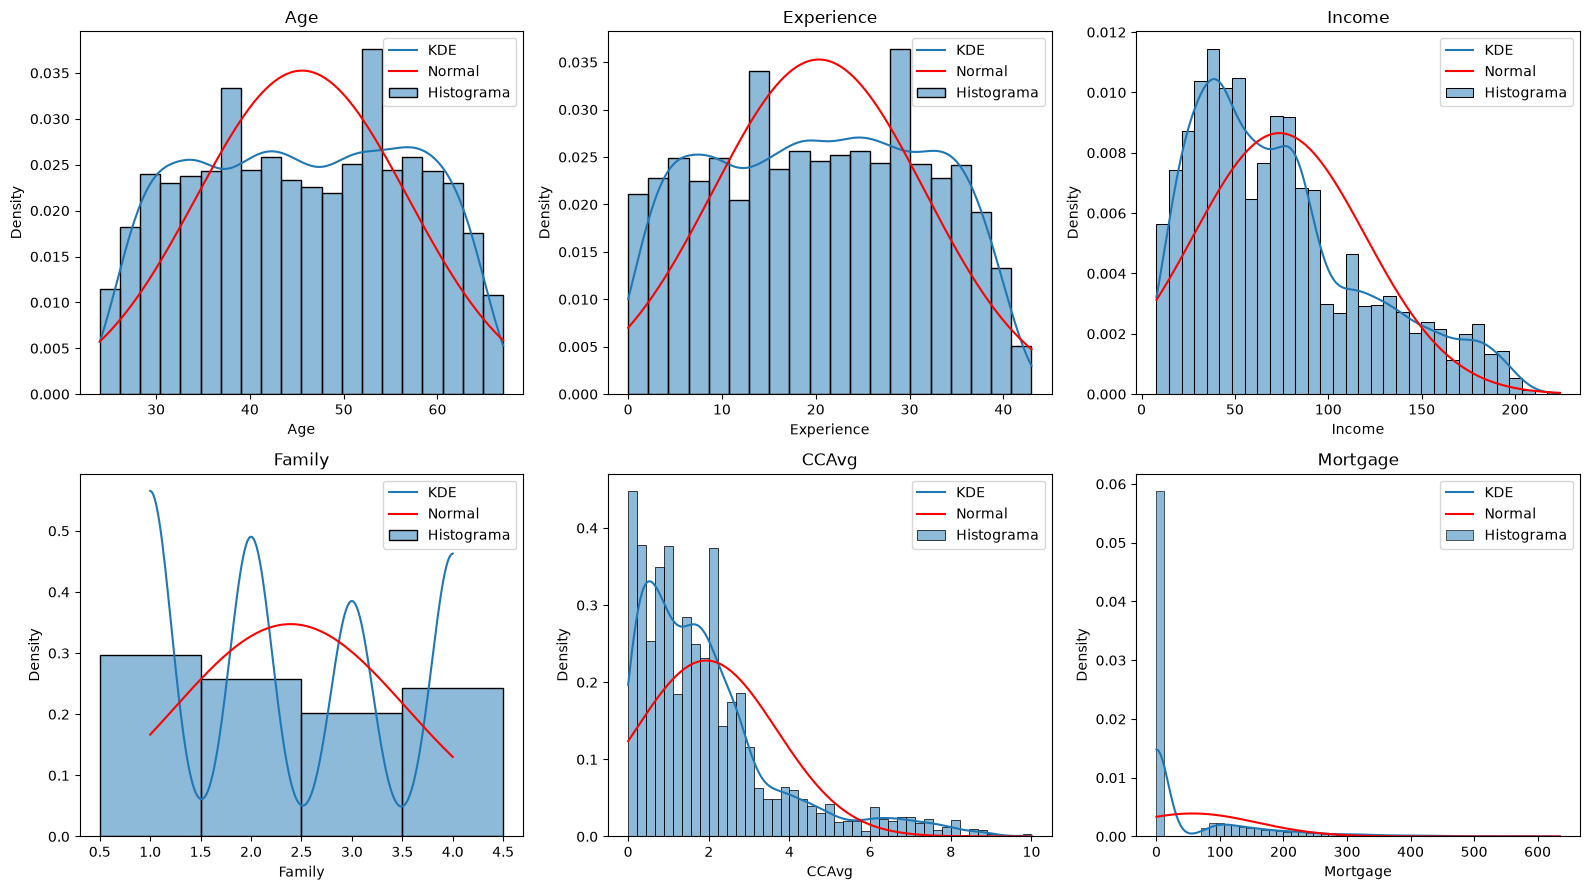

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(loan_df[col], kde=True, stat="density", discrete=loan_df[col].nunique() <= 10, label="Histograma",
                 line_kws={"label": "KDE", "color": "orange"}, ax=ax)
    x = np.linspace(loan_df[col].min(), loan_df[col].max(), 200)
    ax.plot(x, norm.pdf(x, loan_df[col].mean(), loan_df[col].std()), color="red", label="Normal")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

**Respuesta 7 (histogramas).** Las formas coinciden con los valores calculados, y ninguna variable sigue la curva normal de referencia (roja):

* **`Age`:** el histograma es casi plano y simétrico, sin el pico central de la normal, lo que concuerda con la asimetría ≈ 0 y la curtosis negativa (platicúrtica).
* **`Income`:** la mayor parte de los datos está en ingresos bajos y la cola se alarga a la derecha, lo que concuerda con la asimetría positiva moderada. La curtosis ≈ 0 solo indica que el grosor de las colas es similar al de la normal, no que la forma sea normal.
* **`Mortgage`:** hay un pico muy alto en 0 (la mediana es 0) y una cola larga a la derecha, lo que concuerda con la asimetría fuerte y la curtosis alta (leptocúrtica).

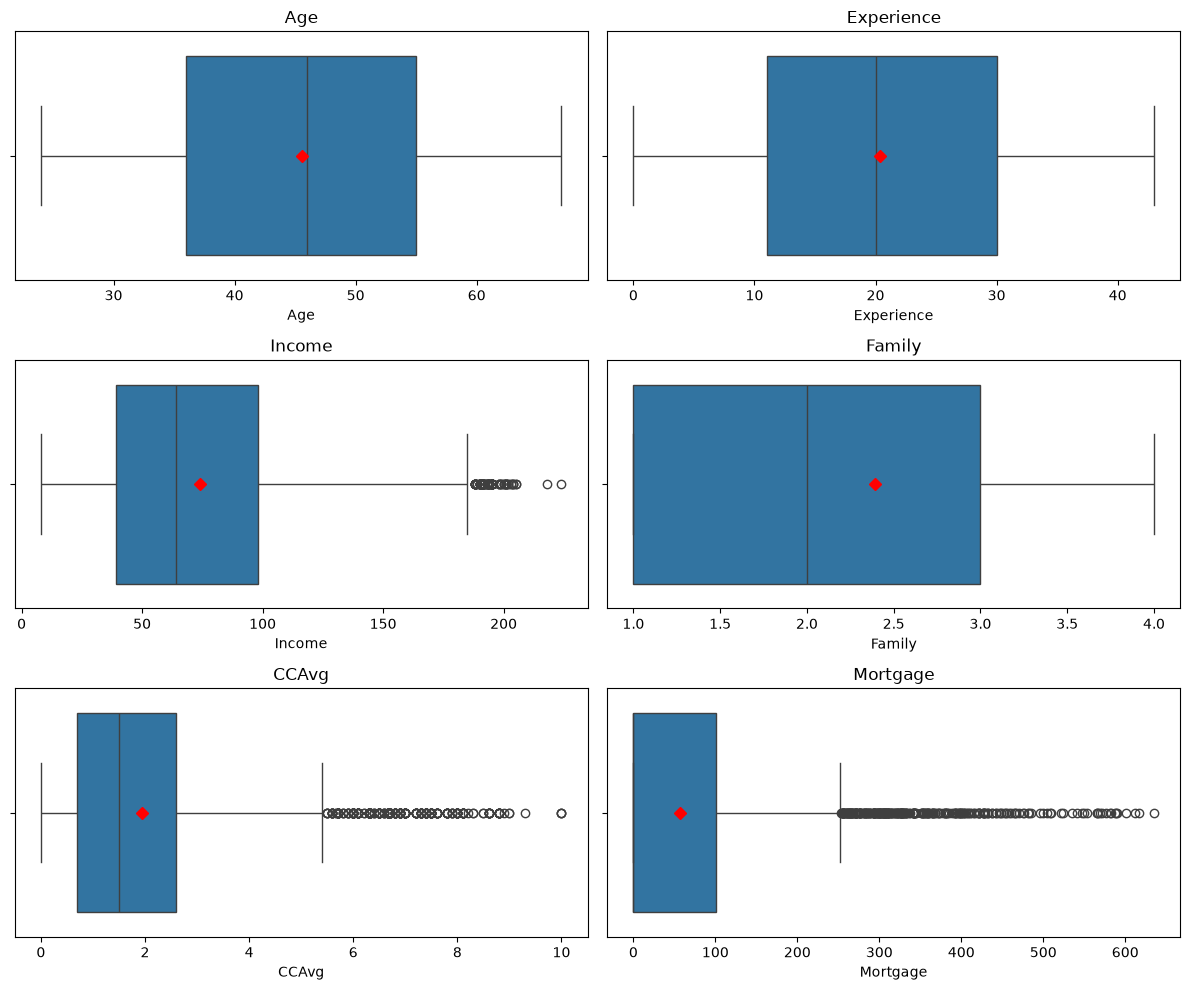

In [22]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=loan_df[col], showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "red"}, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Respuesta 7 (media vs. mediana).** En los boxplots el rombo rojo es la media. Si la media es mayor que la mediana, la distribución tiene sesgo a la derecha; si es menor, sesgo a la izquierda; y si son similares, es simétrica.

* **`Age`** (45.56 vs. 46) y **`Experience`** (20.34 vs. 20): media ≈ mediana, distribución simétrica y sin valores atípicos.
* **`Income`** (73.83 vs. 64), **`CCAvg`** (1.94 vs. 1.5) y **`Mortgage`** (56.66 vs. 0): la media es mayor que la mediana porque los valores atípicos altos la jalan hacia la derecha, lo que indica asimetría positiva.
* **`Family`** (2.39 vs. 2): diferencia pequeña, consistente con su asimetría baja (0.16).

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [23]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


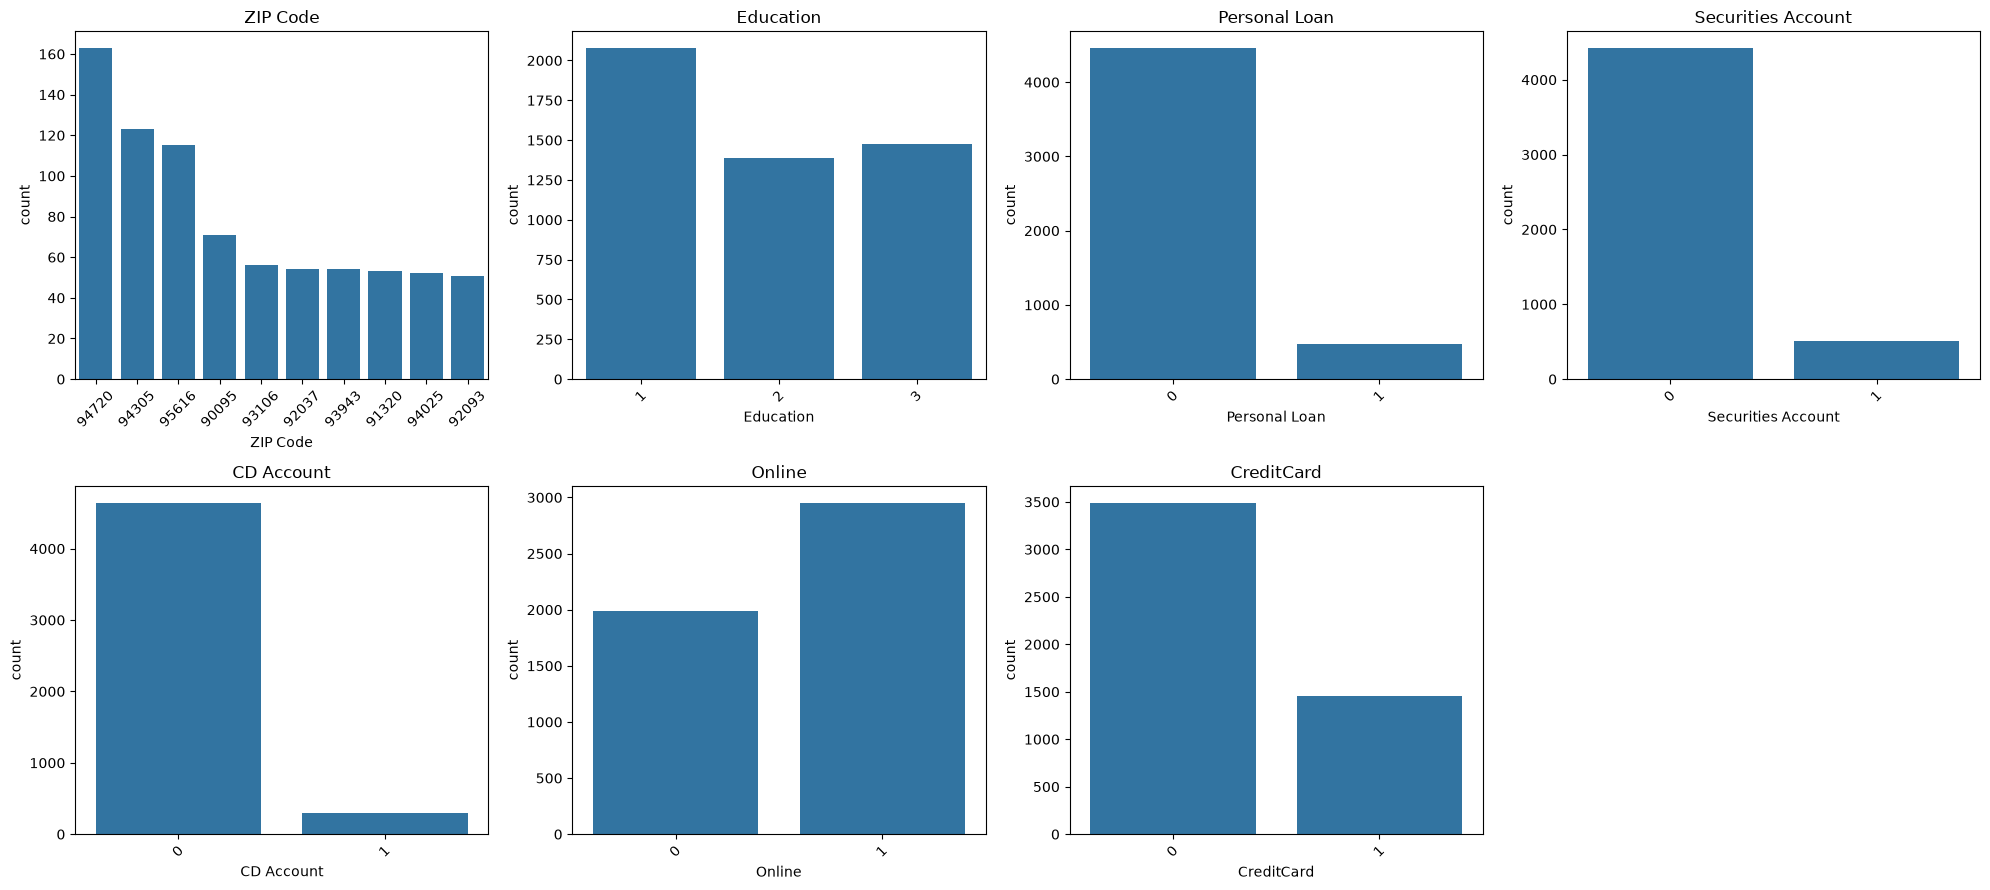

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, cat_cols):
    orden = loan_df[col].value_counts().index[:10] if loan_df[col].nunique() > 10 else None
    sns.countplot(data=loan_df, x=col, order=orden, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

**Respuesta 8.** `Personal Loan`, `Securities Account`, `CD Account` y `CreditCard` están desbalanceadas hacia 0 (por ejemplo, en `Personal Loan` la clase 0 tiene 4,462 de 4,941 registros), mientras que en `Online` predomina el 1. En `Education` el nivel más frecuente es el 1. `ZIP Code` tiene 467 valores distintos (alta cardinalidad), por lo que se grafican solo los 10 más frecuentes, encabezados por 94720 (163 registros).

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

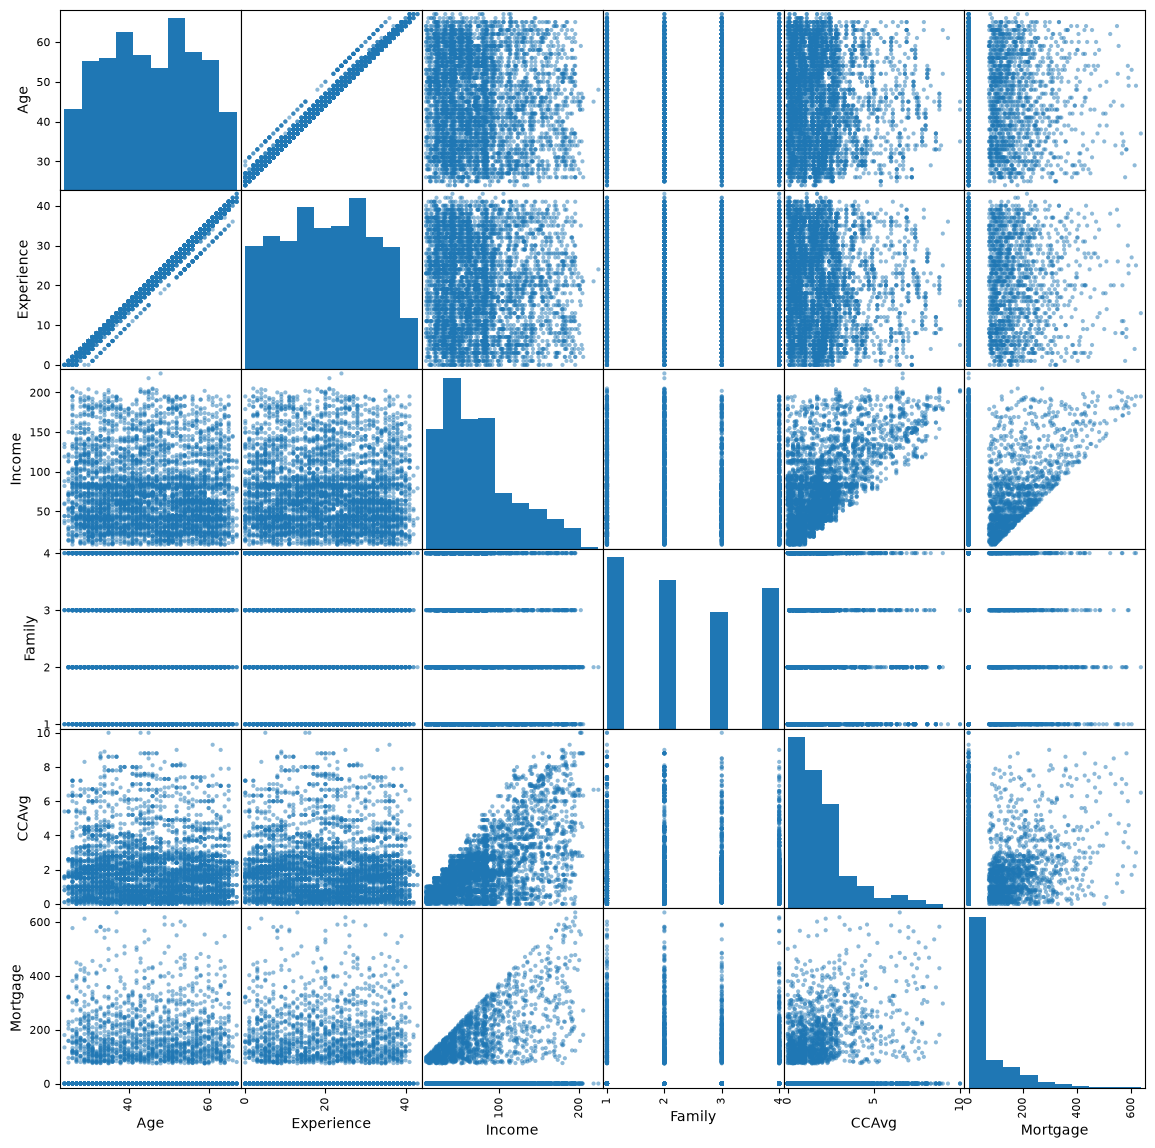

In [25]:
pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(14, 14), diagonal="hist")
plt.show()

**Par representativo: `Age` – `Experience`.** Los puntos forman una línea ascendente casi perfecta: a mayor edad, más años de experiencia, es decir, una relación lineal positiva muy fuerte y con muy poca dispersión. También se observa una tendencia positiva, en forma de abanico, entre `Income` y `CCAvg` y entre `Income` y `Mortgage`; el resto de los pares no muestra un patrón claro.

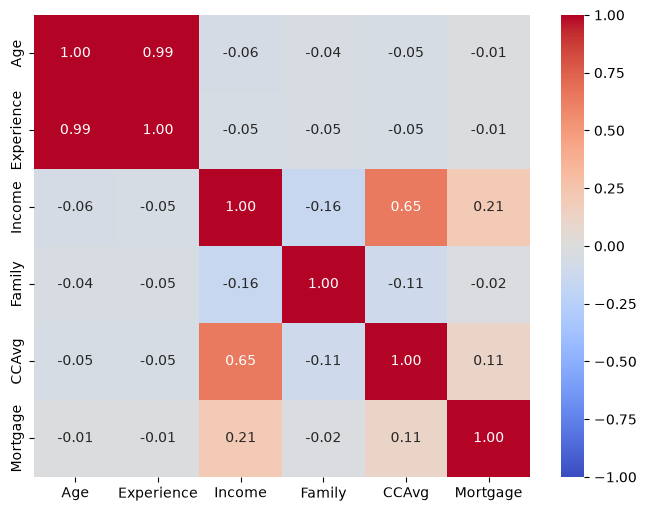

In [26]:
plt.figure(figsize=(8, 6))
sns.heatmap(loan_df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

**Respuesta 9.** Sí se corresponde con lo esperado: la correlación entre `Age` y `Experience` es **0.99**, muy cercana a 1, igual que la línea casi perfecta del scatter. Los demás pares tienen correlaciones bajas, salvo `Income`–`CCAvg` (0.65, positiva moderada).

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


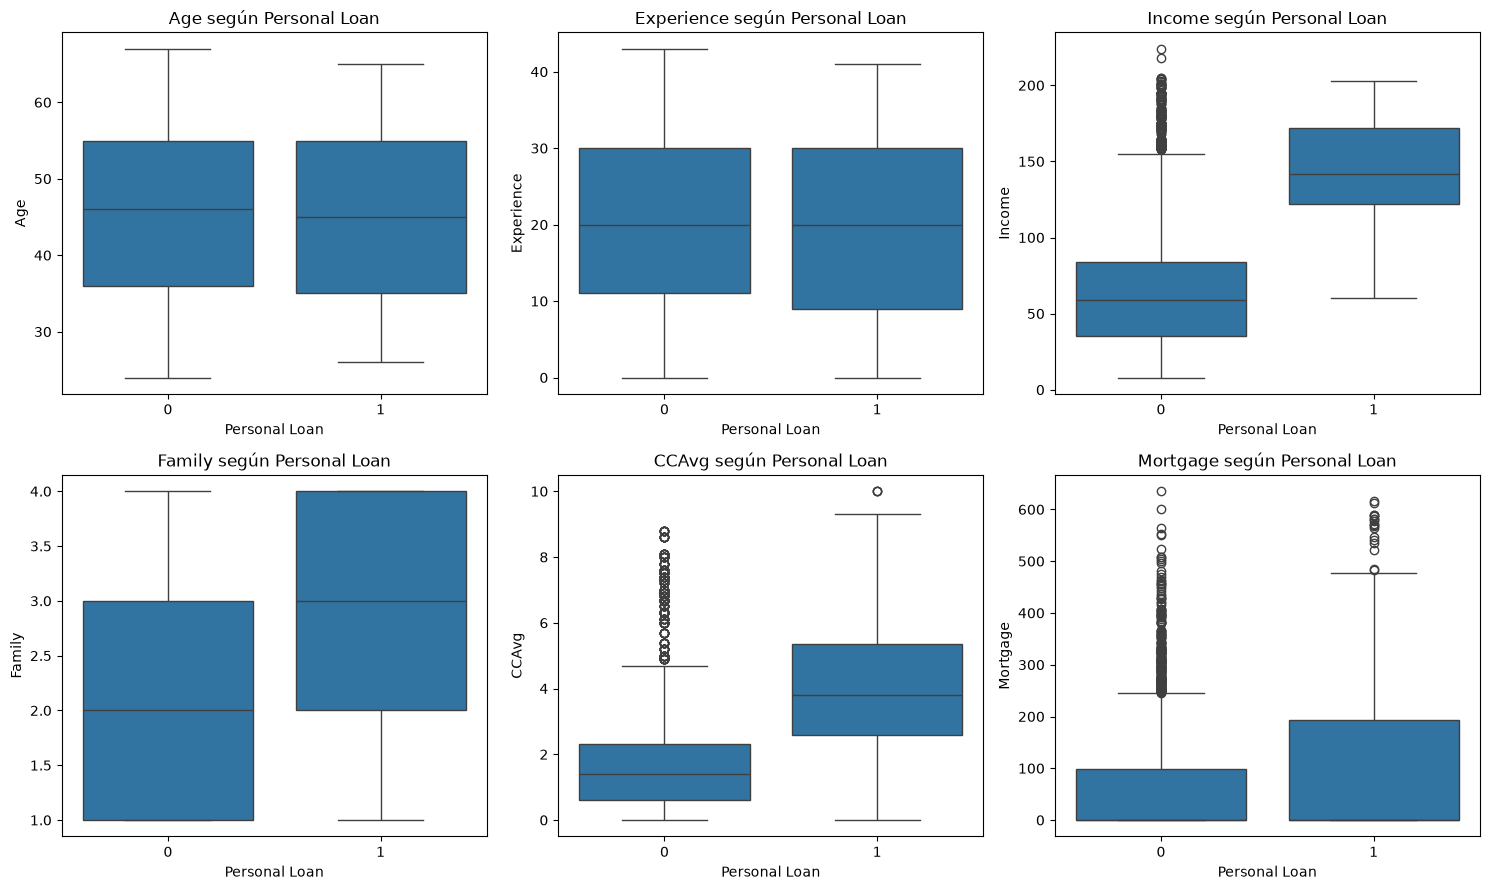

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=loan_df, x="Personal Loan", y=col, ax=ax)
    ax.set_title(f"{col} según Personal Loan")
plt.tight_layout()
plt.show()

**Respuesta 10 (numéricas).** `Income` es la variable que mejor separa los grupos: la mediana de quienes aceptaron el préstamo (≈ 140) es más del doble que la de quienes no (≈ 60) y las cajas casi no se traslapan. `CCAvg` (≈ 3.8 vs. ≈ 1.4) y, en menor medida, `Family` y `Mortgage` también son mayores en quienes aceptaron. En cambio, `Age` y `Experience` tienen distribuciones casi iguales en ambos grupos, por lo que no los distinguen.

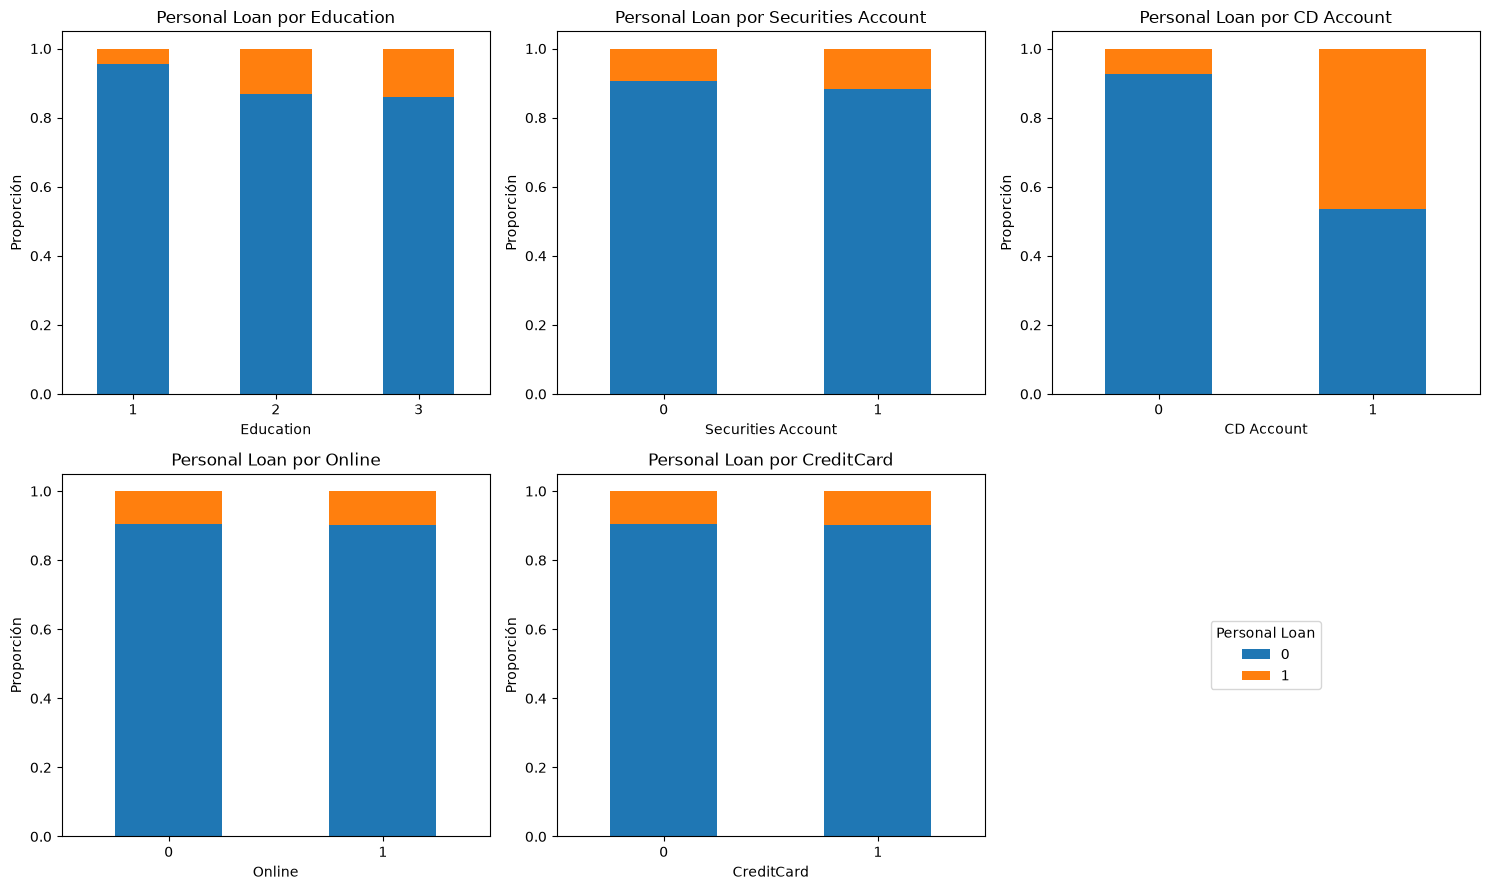

In [28]:
cat_vars = [col for col in cat_cols if col not in ["ZIP Code", "Personal Loan"]]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, cat_vars):
    pd.crosstab(loan_df[col], loan_df["Personal Loan"], normalize="index").plot(kind="bar", stacked=True, rot=0, legend=False, ax=ax)
    ax.set_title(f"Personal Loan por {col}")
    ax.set_ylabel("Proporción")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles, labels, title="Personal Loan", loc="center")
plt.tight_layout()
plt.show()

**Respuesta 10 (categóricas).** Se excluyen `ZIP Code` y la propia `Personal Loan`. `CD Account` muestra el patrón más claro: entre quienes tienen cuenta CD cerca de la mitad (≈ 46 %) aceptó el préstamo, frente a menos del 10 % de quienes no la tienen. En `Education`, la proporción de aceptación es mucho menor en el nivel 1 que en los niveles 2 y 3. En cambio, `Online`, `CreditCard` y `Securities Account` casi no cambian entre categorías, por lo que aportan poca información sobre la aceptación.

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude Code (basado en Claude Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para generación de código, depuración y redacción de los análisis. https://claude.com/claude-code

---